# 04 K-means clustering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')

In [2]:
data = pd.read_csv('../data/processed/standardized_2019.csv')
raw = pd.read_csv('../data/processed/countries_2019.csv')
names = ['GDP_PC', 'GDP_GROWTH', 'INFLATION', 'UNEMPLOYMENT', 'TRADE', 'CAPITAL_FORMATION',
         'LIFE_EXPECTANCY', 'URBAN_POP', 'INTERNET_USERS', 'ELECTRICITY_ACCESS', 'SECONDARY_ENROLLMENT']
income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
X = data[names].values
print(X.shape)

(186, 11)


## Choosing K

In [3]:
inertia = []
silhouette_scores = []
K_range = range(2, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=42)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))
pd.DataFrame({'K': K_range, 'WCSS': inertia, 'silhouette': silhouette_scores}).round(3)

,K,WCSS,silhouette
0,2,1367.498,0.313
1,3,1195.025,0.187
2,4,1073.878,0.192
3,5,989.373,0.186
4,6,910.799,0.177
5,7,849.832,0.167
6,8,807.713,0.146
7,9,774.220,0.140
8,10,734.057,0.154


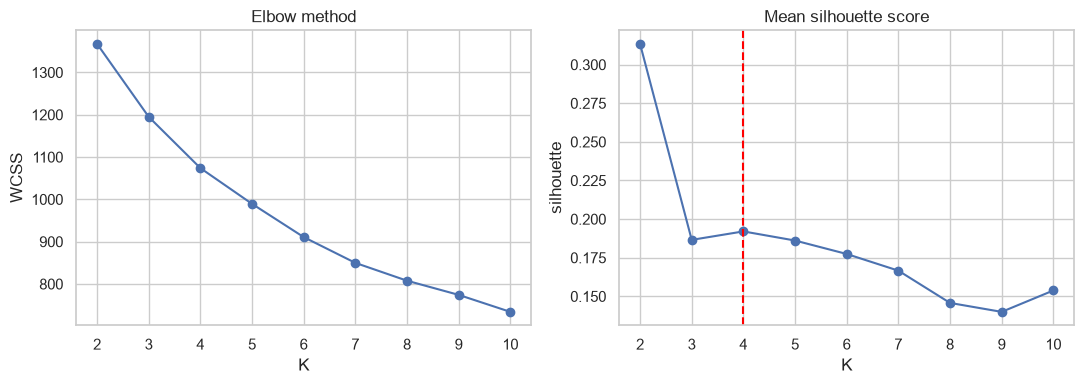

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(K_range, inertia, marker='o')
axes[0].set_title('Elbow method')
axes[0].set_xlabel('K')
axes[0].set_ylabel('WCSS')
axes[1].plot(K_range, silhouette_scores, marker='o')
axes[1].set_title('Mean silhouette score')
axes[1].set_xlabel('K')
axes[1].set_ylabel('silhouette')
axes[1].axvline(4, color='red', linestyle='--')
plt.tight_layout()
plt.savefig('../figures/04_k_selection.png', dpi=200)
plt.show()

## Local optima with a single start

In [5]:
single = []
for seed in range(30):
    kmeans = KMeans(n_clusters=4, init='k-means++', n_init=1, random_state=seed)
    kmeans.fit(X)
    single.append(kmeans.inertia_)
single = np.array(single)
print('WCSS with one start, 30 seeds: min', single.min().round(1), 'max', single.max().round(1))
print('different results:', len(np.unique(single.round(1))))

WCSS with one start, 30 seeds: min 1073.7 max 1154.5
different results: 29


## Final model, K = 4

In [6]:
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=42)
data['cluster'] = kmeans.fit_predict(X)
print('WCSS:', round(kmeans.inertia_, 1))

means = data.groupby('cluster')['GDP_PC'].mean().sort_values()
new_label = {}
for i, old in enumerate(means.index):
    new_label[old] = i
data['cluster'] = data['cluster'].map(new_label)

unemployment = data.groupby('cluster')['UNEMPLOYMENT'].mean()
cluster_names = {0: 'Low development', 3: 'High development'}
if unemployment[1] > unemployment[2]:
    cluster_names[1] = 'Stagnating, high unemployment'
    cluster_names[2] = 'Dynamic emerging'
else:
    cluster_names[1] = 'Dynamic emerging'
    cluster_names[2] = 'Stagnating, high unemployment'
order = []
for i in range(4):
    order.append(cluster_names[i])
data['cluster_name'] = data['cluster'].map(cluster_names)
raw['cluster_name'] = data['cluster_name']
data['cluster_name'].value_counts()

WCSS: 1073.9


cluster_name
High development                 68
Dynamic emerging                 54
Low development                  34
Stagnating, high unemployment    30
Name: count, dtype: int64

## Cluster profiles

In [7]:
profile = raw.groupby('cluster_name')[names].median().T
profile = profile[order]
profile.loc['countries'] = raw['cluster_name'].value_counts()
profile.round(1)

cluster_name,Low development,"Stagnating, high unemployment",Dynamic emerging,High development
GDP_PC,905.5,3785.0,4490.2,30540.5
GDP_GROWTH,5.1,0.5,4.4,1.9
INFLATION,3.3,3.9,1.9,1.6
UNEMPLOYMENT,3.2,16.1,5.4,4.5
TRADE,49.9,69.0,84.9,92.2
CAPITAL_FORMATION,22.7,16.0,26.6,23.0
LIFE_EXPECTANCY,62.5,69.5,72.2,81.4
URBAN_POP,34.8,68.4,55.0,79.6
INTERNET_USERS,17.3,54.1,62.6,86.5
ELECTRICITY_ACCESS,42.6,85.4,99.4,100.0


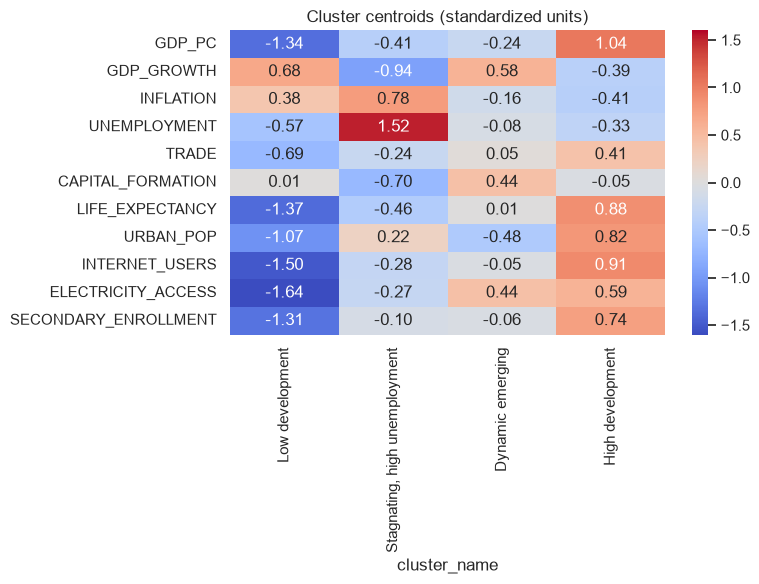

In [8]:
centroids = data.groupby('cluster_name')[names].mean().T
centroids = centroids[order]
plt.figure(figsize=(8, 6))
sns.heatmap(centroids, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.6, vmax=1.6)
plt.title('Cluster centroids (standardized units)')
plt.tight_layout()
plt.savefig('../figures/04_centroids.png', dpi=200)
plt.show()

In [9]:
print('mean silhouette:', round(silhouette_score(X, data['cluster']), 3))

mean silhouette: 0.192


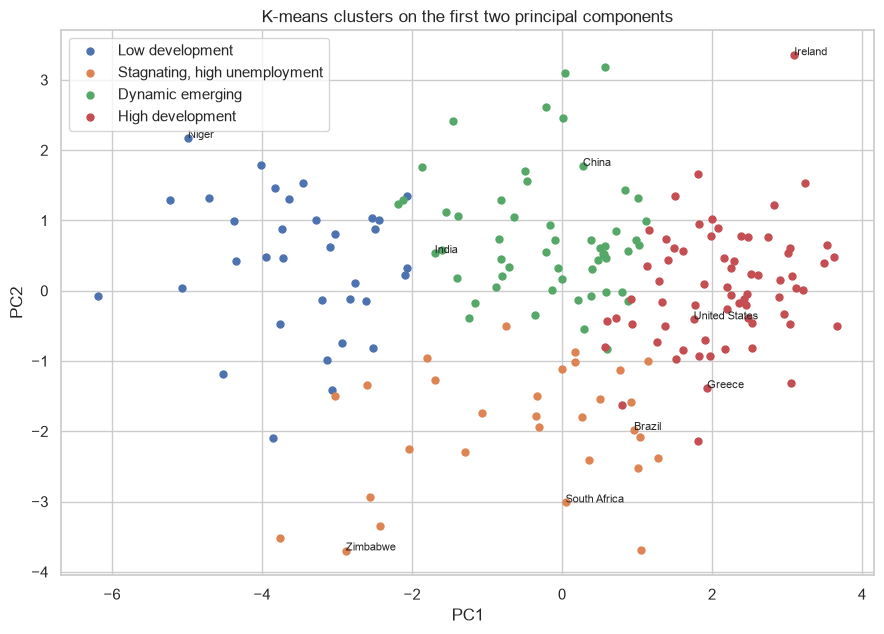

In [10]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
data['PC1'] = X_2d[:, 0]
data['PC2'] = X_2d[:, 1]
if pca.components_[0][0] < 0:
    data['PC1'] = -data['PC1']
if pca.components_[1][1] < 0:
    data['PC2'] = -data['PC2']

plt.figure(figsize=(9, 6.5))
for name in order:
    part = data[data['cluster_name'] == name]
    plt.scatter(part['PC1'], part['PC2'], s=25, label=name)
for country in ['India', 'China', 'Ireland', 'South Africa', 'Zimbabwe', 'Greece', 'United States', 'Brazil', 'Niger']:
    row = data[data['country'] == country]
    plt.annotate(country, (row['PC1'].values[0], row['PC2'].values[0]), fontsize=8)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-means clusters on the first two principal components')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/04_clusters_pca.png', dpi=200)
plt.show()

In [11]:
for name in order:
    print(name, ':', list(data[data['cluster_name'] == name]['country']))
    print()

Low development : ['Afghanistan', 'Burundi', 'Benin', 'Burkina Faso', 'Central African Republic', "Côte d'Ivoire", 'Cameroon', 'Congo, Dem. Rep.', 'Comoros', 'Ethiopia', 'Ghana', 'Guinea', 'Gambia, The', 'Guinea-Bissau', 'Kenya', 'Liberia', 'Madagascar', 'Mali', 'Myanmar', 'Mozambique', 'Mauritania', 'Malawi', 'Niger', 'Nigeria', 'Pakistan', 'Papua New Guinea', 'Rwanda', 'Senegal', 'Sierra Leone', 'Chad', 'Togo', 'Tanzania', 'Uganda', 'Zambia']

Stagnating, high unemployment : ['Angola', 'Argentina', 'Brazil', 'Botswana', 'Congo, Rep.', 'Djibouti', 'Gabon', 'Equatorial Guinea', 'Haiti', 'Iran, Islamic Rep.', 'Jordan', 'Lebanon', 'Libya', 'St. Lucia', 'Lesotho', 'Namibia', 'Nicaragua', 'West Bank and Gaza', 'Sudan', 'Somalia, Fed. Rep.', 'São Tomé and Principe', 'Eswatini', 'Syrian Arab Republic', 'Tunisia', 'Türkiye', 'Ukraine', 'St. Vincent and the Grenadines', 'Venezuela, RB', 'South Africa', 'Zimbabwe']

Dynamic emerging : ['Albania', 'Armenia', 'Antigua and Barbuda', 'Azerbaijan', 

## Comparison with income groups

In [12]:
pd.crosstab(data['cluster_name'], data['income_group'])[income_order].loc[order]

income_group,Low income,Lower middle income,Upper middle income,High income
cluster_name,,,,
Low development,18,16,0,0
"Stagnating, high unemployment",3,14,13,0
Dynamic emerging,0,17,32,5
High development,0,0,7,61


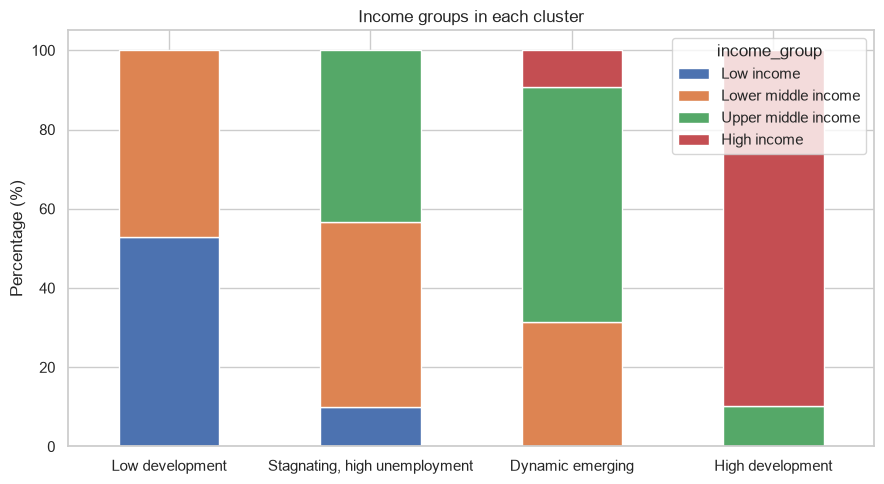

In [13]:
ct = pd.crosstab(data['cluster_name'], data['income_group'], normalize='index') * 100
ct = ct[income_order].loc[order]
ct.plot(kind='bar', stacked=True, figsize=(9, 5))
plt.ylabel('Percentage (%)')
plt.xlabel('')
plt.xticks(rotation=0)
plt.title('Income groups in each cluster')
plt.tight_layout()
plt.savefig('../figures/04_clusters_vs_income.png', dpi=200)
plt.show()

In [14]:
(pd.crosstab(data['income_group'], data['cluster_name'], normalize='index') * 100).loc[income_order][order].round(1)

cluster_name,Low development,"Stagnating, high unemployment",Dynamic emerging,High development
income_group,,,,
Low income,85.7,14.3,0.0,0.0
Lower middle income,34.0,29.8,36.2,0.0
Upper middle income,0.0,25.0,61.5,13.5
High income,0.0,0.0,7.6,92.4


## Comparison with regions

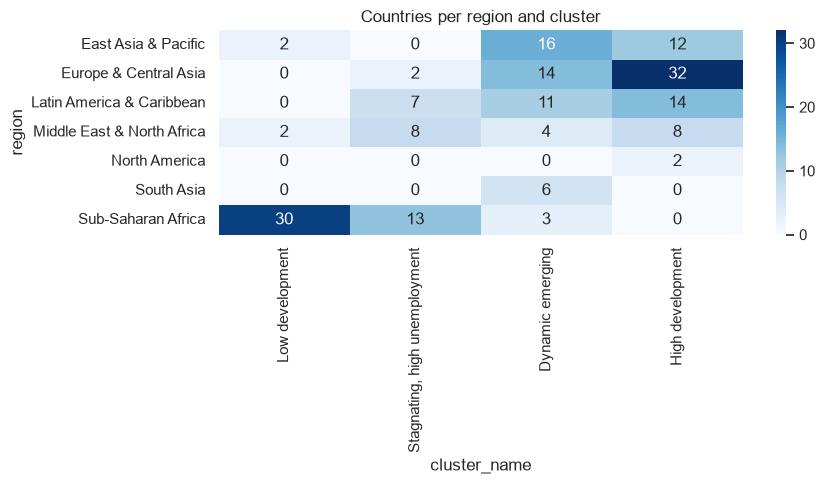

In [15]:
region_ct = pd.crosstab(data['region'], data['cluster_name'])[order]
plt.figure(figsize=(9, 5))
sns.heatmap(region_ct, annot=True, fmt='d', cmap='Blues')
plt.title('Countries per region and cluster')
plt.tight_layout()
plt.savefig('../figures/04_clusters_vs_region.png', dpi=200)
plt.show()

## Unusual countries

In [16]:
centroid_values = data.groupby('cluster')[names].mean().values
own_centroid = centroid_values[data['cluster'].values]
data['distance'] = np.sqrt(((X - own_centroid) ** 2).sum(axis=1))
data.sort_values('distance', ascending=False)[['country', 'cluster_name', 'income_group', 'distance']].head(12)

,country,cluster_name,income_group,distance
46,Djibouti,"Stagnating, high unemployment",Lower middle income,4.697255
76,Ireland,High development,High income,4.569737
28,Central African Republic,Low development,Low income,4.347826
147,Sudan,"Stagnating, high unemployment",Low income,4.328139
185,Zimbabwe,"Stagnating, high unemployment",Lower middle income,4.193669
77,"Iran, Islamic Rep.","Stagnating, high unemployment",Upper middle income,4.100239
160,Eswatini,"Stagnating, high unemployment",Lower middle income,4.092815
94,Liberia,Low development,Low income,4.063709
5,Argentina,"Stagnating, high unemployment",Upper middle income,3.866684
108,Marshall Islands,Dynamic emerging,Upper middle income,3.811426


In [17]:
for country in ['Ireland', 'Greece', 'Spain', 'Venezuela, RB', 'Zimbabwe', 'Djibouti']:
    row = data[data['country'] == country]
    deviation = (row[names].values[0] - centroid_values[row['cluster'].values[0]]).round(1)
    print(country, '-', row['cluster_name'].values[0])
    print(pd.Series(deviation, index=names).sort_values())
    print()

Ireland - High development
URBAN_POP              -0.7
INFLATION              -0.2
UNEMPLOYMENT           -0.1
ELECTRICITY_ACCESS      0.0
INTERNET_USERS          0.1
LIFE_EXPECTANCY         0.4
GDP_PC                  0.7
SECONDARY_ENROLLMENT    1.1
GDP_GROWTH              1.2
TRADE                   1.9
CAPITAL_FORMATION       3.6
dtype: float64

Greece - High development
CAPITAL_FORMATION      -1.5
INFLATION              -0.4
TRADE                  -0.3
GDP_PC                 -0.3
INTERNET_USERS         -0.3
URBAN_POP              -0.0
ELECTRICITY_ACCESS      0.0
SECONDARY_ENROLLMENT   -0.0
GDP_GROWTH              0.2
LIFE_EXPECTANCY         0.2
UNEMPLOYMENT            2.1
dtype: float64

Spain - High development
TRADE                  -0.7
CAPITAL_FORMATION      -0.4
INFLATION              -0.3
GDP_PC                  0.0
URBAN_POP               0.0
ELECTRICITY_ACCESS      0.0
GDP_GROWTH              0.1
INTERNET_USERS          0.2
SECONDARY_ENROLLMENT    0.5
LIFE_EXPECTANCY       

In [18]:
print('High income outside High development:')
print(list(data[(data['income_group'] == 'High income') & (data['cluster'] != 3)]['country']))
print('Upper middle income in High development:')
print(list(data[(data['income_group'] == 'Upper middle income') & (data['cluster'] == 3)]['country']))
print('Low income outside Low development:')
print(list(data[(data['income_group'] == 'Low income') & (data['cluster'] != 0)]['country']))

High income outside High development:
['Antigua and Barbuda', 'Guyana', 'Panama', 'Romania', 'Seychelles']
Upper middle income in High development:
['Belarus', 'Cuba', 'Ecuador', 'Mexico', 'Malaysia', 'Peru', 'Paraguay']
Low income outside Low development:
['Sudan', 'Somalia, Fed. Rep.', 'Syrian Arab Republic']


## Robustness

In [19]:
def agreement(labels_a, labels_b):
    table = pd.crosstab(labels_a, labels_b)
    a_to_b = table.max(axis=1).sum()
    b_to_a = table.max(axis=0).sum()
    return min(a_to_b, b_to_a) / len(labels_a)

for seed in [1, 2, 3, 4, 5]:
    other = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=seed).fit_predict(X)
    print(f'seed {seed}: {agreement(data["cluster"], other) * 100:.1f}%')

seed 1: 100.0%


seed 2: 98.4%


seed 3: 100.0%


seed 4: 97.8%


seed 5: 97.8%


In [20]:
X_3 = PCA(n_components=3).fit_transform(X)
labels_3 = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=42).fit_predict(X_3)
print(f'first 3 PCs: {agreement(data["cluster"], labels_3) * 100:.1f}%')
pd.crosstab(data['cluster_name'], labels_3)

first 3 PCs: 91.4%


col_0,0,1,2,3
cluster_name,,,,
Dynamic emerging,0,4,49,1
High development,60,0,5,3
Low development,0,34,0,0
"Stagnating, high unemployment",0,3,0,27


In [21]:
complete = data[data['complete']]
X_complete = complete[names].values
labels_complete = KMeans(n_clusters=4, init='k-means++', n_init=50, random_state=42).fit_predict(X_complete)
print('countries with no imputed value:', len(complete))
print(f'agreement: {agreement(complete["cluster"], labels_complete) * 100:.1f}%')
pd.crosstab(complete['cluster_name'], labels_complete)

countries with no imputed value: 136
agreement: 72.8%


col_0,0,1,2,3
cluster_name,,,,
Dynamic emerging,2,0,20,19
High development,47,0,0,10
Low development,0,20,3,0
"Stagnating, high unemployment",0,3,0,12


## Save

In [22]:
data.to_csv('../data/processed/kmeans_clusters.csv', index=False)